**ANOMALY DETECTION ANALYSIS**

In [ ]:
import digitalhub as dh
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [15]:
job_name = "analisi_net_v3_ocsvm"

parameters = {
    "results_job": "net_v3_ocsvm",     # job OC-SVM da analizzare: legge l'artifact anomaly_results_{results_job}
    "dataset_masks": "",               # artifact con MASK/ ("" = dataset_anomalies scritto nel JSON del job)
    "flood_class": 2,                  # classe flood nella maschera
    "nu": 0.0,                         # 0 = quello del job
    "otsu_bins": 64,                   # classi dell'istogramma per le soglie di Otsu
    "n_flood_bins": 4,                 # gruppi di anomale per frazione di flood
    "job_name": job_name,              # i risultati escono come analisi_embeddings_{job_name}
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "500Gi"}      # il download dell'artifact con le maschere scarica tutto l'artifact
    }
]

**BUILD ENVIRONMENT**

In [ ]:
analisi_func = project.new_function(
    name=f'analyzeAnomalyEmbeddings_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="anomaly:analyze_anomalies",
    base_image="pytorch/pytorch:2.1.2-cuda11.8-cudnn8-runtime",     # stesso ambiente degli altri handler in src
    requirements=["pandas==2.3.3", "numpy==1.26.4", "rasterio==1.4.4", "tqdm==4.70.0", "tifffile==2024.8.30", "torch==2.1.2", "matplotlib==3.10.9", "digitalhub==0.15.11", "digitalhub-runtime-python==0.15.2", "zarr==2.18.0", "numcodecs==0.13.1", "xarray==2025.6.1", "scikit-learn==1.5.2"]
)

build = analisi_func.run("build", wait=True)
print(f"BUILD: {build.status.state}")

2026-10-07 18:29:21,293 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run e5f9025a7c2244a4b57995880965506d to finish...
2026-10-07 18:29:26,303 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run e5f9025a7c2244a4b57995880965506d to finish...
2026-10-07 18:29:31,315 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run e5f9025a7c2244a4b57995880965506d to finish...
2026-10-07 18:29:36,327 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run e5f9025a7c2244a4b57995880965506d to finish...
2026-10-07 18:29:41,338 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run e5f9025a7c2244a4b57995880965506d to finish...
2026-10-07 18:29:46,348 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run e5f9025a7c2244a4b57995880965506d to finish...
2026-10-07 18:29:51,361 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run e5f9025a7c2244a4b57995880965506d to finish...
2026-10-07 18

BUILD: COMPLETED


**ANALISI** (nessuna GPU necessaria: usa il profilo CPU che usi per visualize_flood_overlay)

In [17]:
run_an = analisi_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    profile="cpu-shared",
    local_execution=False,
    wait=True
)

print(f"Run analisi avviato: {run_an.id}")

2026-10-07 18:30:21,613 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run a19c3f92ce6646ad82536e3733213609 to finish...
2026-10-07 18:30:26,621 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run a19c3f92ce6646ad82536e3733213609 to finish...
2026-10-07 18:30:31,632 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run a19c3f92ce6646ad82536e3733213609 to finish...
2026-10-07 18:30:36,746 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run a19c3f92ce6646ad82536e3733213609 to finish...
2026-10-07 18:30:41,757 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run a19c3f92ce6646ad82536e3733213609 to finish...
2026-10-07 18:30:46,770 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run a19c3f92ce6646ad82536e3733213609 to finish...
2026-10-07 18:30:51,885 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run a19c3f92ce6646ad82536e3733213609 to finish...
2026-10-07 18

Run analisi avviato: a19c3f92ce6646ad82536e3733213609


**RESULTS**

In [18]:
RESULTS_DIR = "/tmp/analisi_embeddings"

zip_path = project.get_artifact(f"analisi_embeddings_{job_name}").download("/tmp/analisi_embeddings.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

print(open(f"{RESULTS_DIR}/report.txt").read())

fit 2572 | normali 2402 | anomale 2402 | dim q = dim k = 128 | SE sotto ipotesi nulla = 0.0083
OC-SVM di riferimento: nu=0.05, standardize=True (dal job)
OC-SVM ...
kNN coseno ...
Binarizzazione + Hamming ...

=== AUROC (alto = distingue; 0.5 = caso) ===
coseno q,k: 0.543 ± 0.008

OC-SVM, nu=0.05: ingresso x moltiplicatore di gamma (1.0 = 'scale', come il job)
gm         0.10   0.25   0.50   1.00   2.00   4.00
ingresso                                          
q         0.576  0.577  0.577  0.580  0.604  0.661
k         0.671  0.671  0.669  0.670  0.669  0.669
[q;k]     0.634  0.635  0.635  0.638  0.661  0.688 

OC-SVM [q;k], sensibilita' a nu (gamma=scale):
  nu  auroc    se
0.01  0.638 0.008
0.05  0.638 0.008
0.20  0.652 0.008 

kNN coseno:
ingresso parametri  auroc    se
       q       k=5  0.635 0.008
       q      k=20  0.647 0.008
       k       k=5  0.498 0.008
       k      k=20  0.506 0.008
   [q;k]       k=5  0.569 0.008
   [q;k]      k=20  0.570 0.008 

kNN Hamming:
ingresso

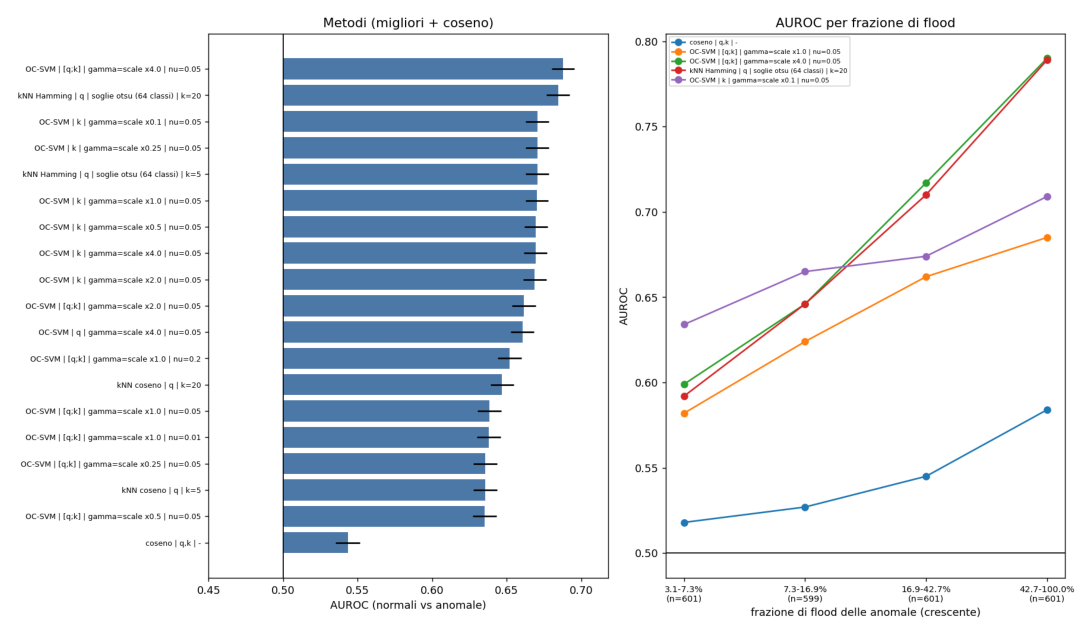

In [19]:
img = plt.imread(f"{RESULTS_DIR}/analisi_embeddings.png")
plt.figure(figsize=(16, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

In [20]:
pd.set_option("display.width", 250, "display.max_columns", 30, "display.max_colwidth", 60)
strat = pd.read_csv(f"{RESULTS_DIR}/stratificazione_flood.csv")
strat

,metodo,"rho(norm., frazione flood)",p,AUROC 3.1-7.3% (n=601),AUROC 7.3-16.9% (n=599),AUROC 16.9-42.7% (n=601),AUROC 42.7-100.0% (n=601)
0,"coseno | q,k | -",-0.080,9.514348e-05,0.518±0.013,0.527±0.013,0.545±0.013,0.584±0.012
1,OC-SVM | [q;k] | gamma=scale x1.0 | nu=0.05,-0.136,2.088518e-11,0.582±0.013,0.624±0.012,0.662±0.011,0.685±0.011
2,OC-SVM | [q;k] | gamma=scale x4.0 | nu=0.05,-0.272,3.857885e-42,0.599±0.012,0.646±0.012,0.717±0.010,0.790±0.009
3,kNN Hamming | q | soglie otsu (64 classi) | k=20,-0.308,7.500458e-54,0.592±0.012,0.646±0.012,0.710±0.011,0.789±0.009
4,OC-SVM | k | gamma=scale x0.1 | nu=0.05,-0.092,5.696242e-06,0.634±0.012,0.665±0.011,0.674±0.011,0.709±0.011
